Melhor C: 0.1
Acurácia: 0.9333333333333333


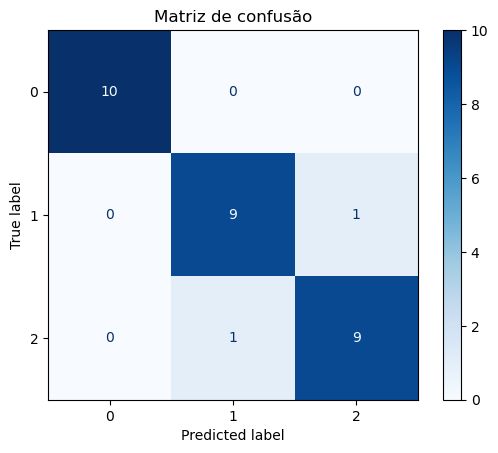

In [ ]:
# 1. Imports
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# 2. Carregar dados
iris = datasets.load_iris()
X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['especie'] = y
print(df.head())

# 3. Dividir treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Padronizar (fit no treino, transform no teste)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# 5. GridSearch: comparar kernels (linear e rbf) com seus hiperparâmetros
param_grid = [
    {'kernel': ['linear'], 'C': [0.1, 1, 10]},
    {'kernel': ['rbf'], 'C': [0.1, 1, 10], 'gamma': [0.1, 1, 'scale']}
]
grid = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train_s, y_train)

# 6. Comparar: melhor combinação de cada kernel
res = pd.DataFrame(grid.cv_results_)
melhores = res.loc[res.groupby('param_kernel')['mean_test_score'].idxmax(),
                   ['param_kernel', 'params', 'mean_test_score']]
print(melhores.to_string(index=False))
print('Melhor geral:', grid.best_params_, round(grid.best_score_, 4))

# 7. Avaliar o melhor modelo no teste
best = grid.best_estimator_
y_pred = best.predict(X_test_s)
print('Acurácia no teste:', accuracy_score(y_test, y_pred))

# 8. Matriz de confusão
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=iris.target_names).plot(cmap='Blues')
plt.title('Matriz de confusão')
plt.show()